# 01. EDA — 데이터 탐색

**목표**
- 클래스별 이미지 수 및 불균형 확인
- 이미지 해상도, 채널 분포 확인
- RGB vs Grayscale 비교
- 이상치 확인
- → 전처리 방향 결정

## 0. 환경 설정

In [43]:
import subprocess, sys

libs = ['matplotlib', 'pandas', 'seaborn', 'Pillow']
for lib in libs:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', lib, '-q'])

## 1. 라이브러리 및 경로 설정

In [44]:
import os, random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

RAW_DIR = Path('..') / 'data' / 'raw'
CLASS_MAP = {'고추': 'pepper', '배추': 'cabbage', '오이': 'cucumber'}
SPLITS = ['Training', 'Validation']
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

print('경로 존재:', RAW_DIR.exists())

경로 존재: True


## 2. 데이터 구조 파악

In [45]:
def get_image_paths(raw_dir, splits, class_map):
    data = defaultdict(list)
    for split in splits:
        split_dir = raw_dir / split
        for folder in split_dir.iterdir():
            if not folder.is_dir() or '[원천]' not in folder.name:
                continue
            for kr_name, en_name in class_map.items():
                if kr_name in folder.name:
                    for f in folder.iterdir():
                        if f.suffix.lower() in IMAGE_EXTS:
                            data[en_name].append(f)
    return data

image_paths = get_image_paths(RAW_DIR, SPLITS, CLASS_MAP)

total = 0
for cls, paths in image_paths.items():
    print(f'{cls:10s}: {len(paths):,}장')
    total += len(paths)
print(f'{"합계":10s}: {total:,}장')

pepper    : 2,705장
cabbage   : 2,008장
cucumber  : 2,227장
합계        : 6,940장


## 3. 클래스별 이미지 수 시각화

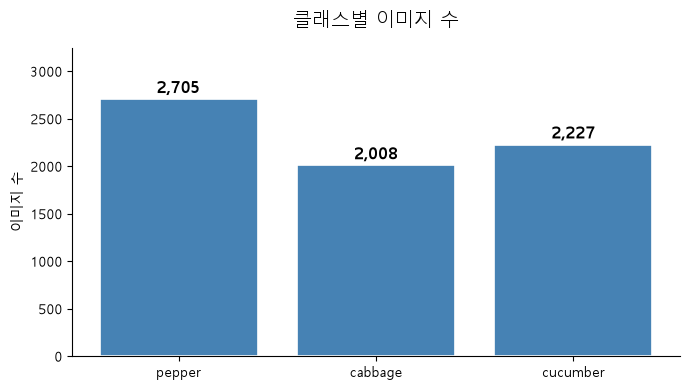

In [46]:
classes = list(image_paths.keys())
counts = [len(image_paths[c]) for c in classes]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(classes, counts, color='steelblue',
              edgecolor='white', linewidth=1.2)

for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f'{count:,}', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title('클래스별 이미지 수', fontsize=14, pad=15)
ax.set_ylabel('이미지 수')
ax.set_ylim(0, max(counts) * 1.2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../results/figures/01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### 결정: 언더샘플링

In [47]:
MAX_PER_CLASS = 2000  # 클래스 불균형 처리 — 언더샘플링
print(f'클래스당 최대 이미지 수: {MAX_PER_CLASS}장')

클래스당 최대 이미지 수: 2000장


## 4. 이미지 크기 분포

In [48]:
sizes = []
for cls, paths in image_paths.items():
    sample = random.sample(paths, min(200, len(paths)))
    for p in sample:
        try:
            w, h = Image.open(p).size
            sizes.append({'class': cls, 'width': w, 'height': h})
        except Exception:
            pass

df_sizes = pd.DataFrame(sizes)

print('=== 전체 이미지 크기 통계 ===')
print(df_sizes[['width', 'height']].describe().round(0))

print('\n=== 고유 해상도 수 ===')
unique = df_sizes.groupby(['width', 'height']).size().reset_index(name='count').sort_values('count', ascending=False)
print(f'총 {len(unique)}가지 해상도')
print(unique.head(10).to_string(index=False))

=== 전체 이미지 크기 통계 ===
        width  height
count   600.0   600.0
mean   3658.0  3054.0
std     898.0   770.0
min     720.0   960.0
25%    3024.0  2196.0
50%    4032.0  3024.0
75%    4032.0  4032.0
max    6000.0  4032.0

=== 고유 해상도 수 ===
총 24가지 해상도
 width  height  count
  4032    3024    191
  3024    4032    159
  4640    2196     74
  1536    2048     34
  4656    3492     31
  3264    1836     23
  5312    2988     15
  4032    1860     13
  4032    2268     10
  4000    3000      9


### 결정: 리사이즈
- 해상도 종류: 클래스당 200장 샘플 기준 25가지 혼재 → 통일 필요
- 최소 해상도: 720 × 720 → 224 × 224 리사이즈 시 업스케일 없음
- 채택 크기: 224 × 224 (CNN 관행적 표준)

In [49]:
IMG_SIZE = 224
print(f'리사이즈 크기: {IMG_SIZE} × {IMG_SIZE}')

리사이즈 크기: 224 × 224


## 5. 샘플 이미지 시각화

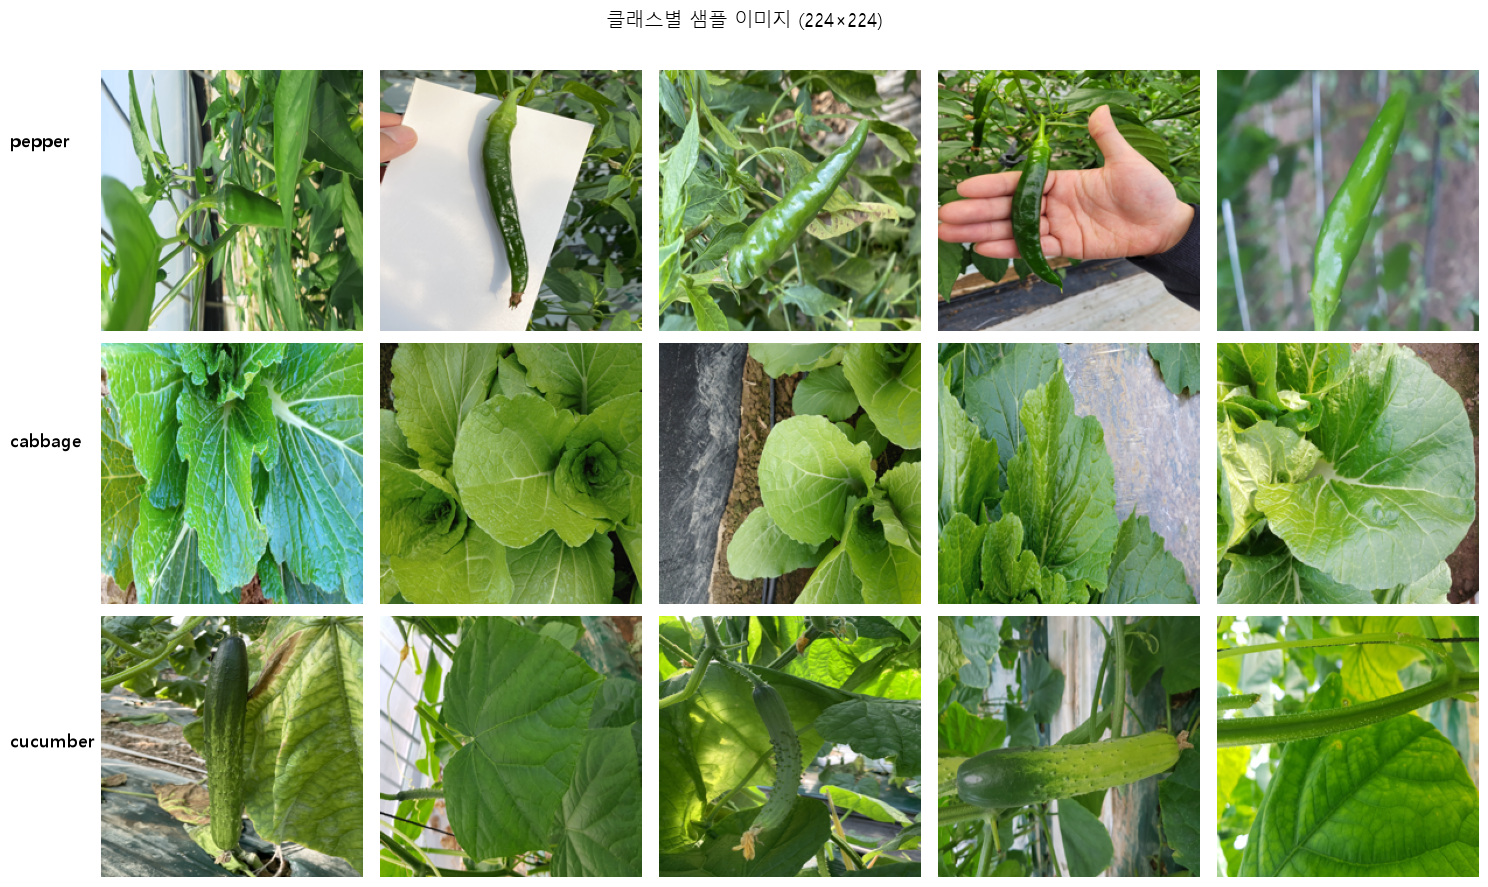

In [50]:
n_samples = 5
classes_list = list(image_paths.keys())
fig, axes = plt.subplots(len(classes_list), n_samples, figsize=(15, 9))

for row, cls in enumerate(classes_list):
    paths = image_paths[cls]
    samples = random.sample(paths, n_samples)
    for col, p in enumerate(samples):
        img = Image.open(p).resize((IMG_SIZE, IMG_SIZE))
        axes[row][col].imshow(img)
        axes[row][col].axis('off')

    fig.text(0.01, 1 - (row + 0.5) / len(classes_list),
             cls, va='center', ha='left', fontsize=13, fontweight='bold')

fig.suptitle('클래스별 샘플 이미지 (224×224)', fontsize=14)
plt.tight_layout(rect=[0.06, 0, 1, 0.97])
plt.savefig('../results/figures/02_sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. RGB vs Grayscale 비교

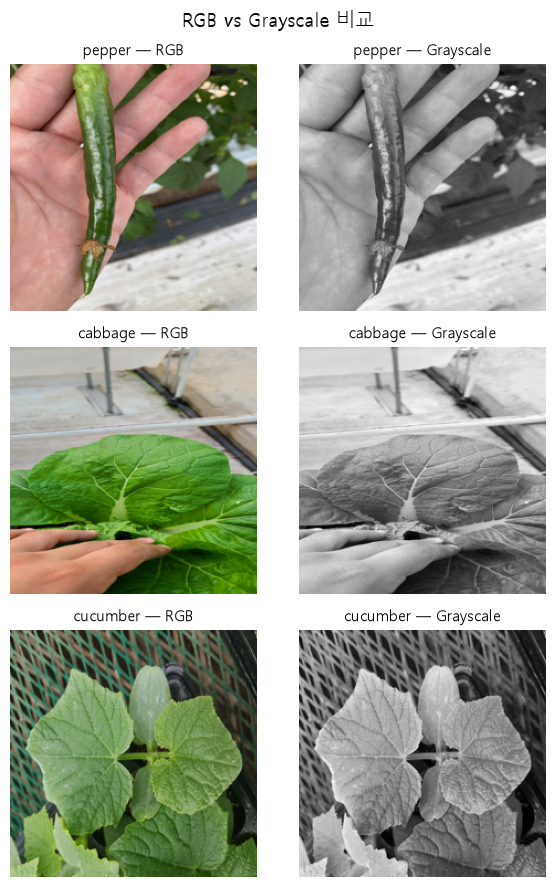

In [51]:
fig, axes = plt.subplots(len(image_paths), 2, figsize=(6, 9))

for row, (cls, paths) in enumerate(image_paths.items()):
    p = random.choice(paths)
    img_rgb = Image.open(p).resize((IMG_SIZE, IMG_SIZE))
    img_gray = img_rgb.convert('L')

    axes[row][0].imshow(img_rgb)
    axes[row][0].axis('off')
    axes[row][0].set_title(f'{cls} — RGB', fontsize=11)

    axes[row][1].imshow(img_gray, cmap='gray')
    axes[row][1].axis('off')
    axes[row][1].set_title(f'{cls} — Grayscale', fontsize=11)

plt.suptitle('RGB vs Grayscale 비교', fontsize=14)
plt.tight_layout()
plt.savefig('../results/figures/03_rgb_vs_gray.png', dpi=150, bbox_inches='tight')
plt.show()

### 클래스별 RGB 채널 분포

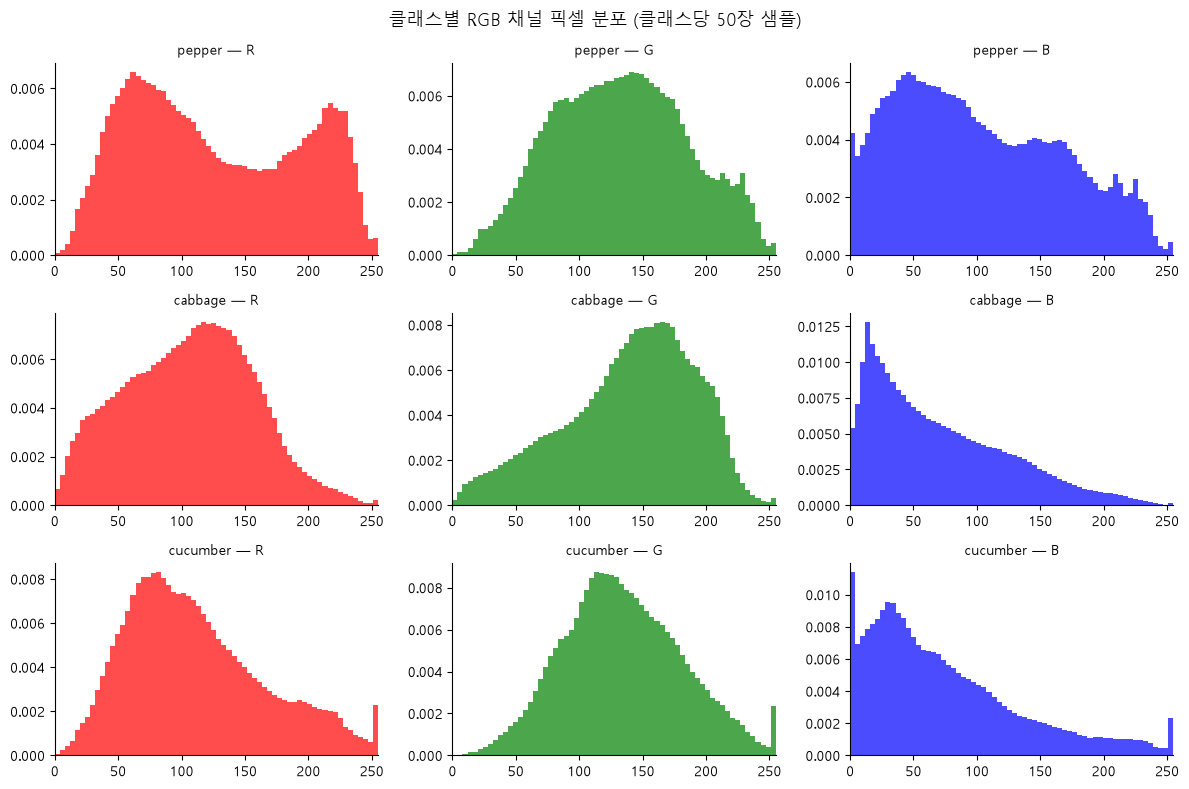

In [52]:
channel_names = ['R', 'G', 'B']
colors = ['red', 'green', 'blue']

fig, axes = plt.subplots(len(image_paths), 3, figsize=(12, 8))

for row, (cls, paths) in enumerate(image_paths.items()):
    sample = random.sample(paths, min(50, len(paths)))
    pixels = []
    for p in sample:
        img = Image.open(p).resize((IMG_SIZE, IMG_SIZE)).convert('RGB')
        pixels.append(np.array(img))
    pixels = np.concatenate([p.reshape(-1, 3) for p in pixels], axis=0)

    for col, (ch, color) in enumerate(zip(range(3), colors)):
        axes[row][col].hist(pixels[:, ch], bins=64, color=color, alpha=0.7, density=True)
        axes[row][col].set_xlim(0, 255)
        axes[row][col].set_title(f'{cls} — {channel_names[col]}', fontsize=10)
        axes[row][col].spines['top'].set_visible(False)
        axes[row][col].spines['right'].set_visible(False)

plt.suptitle('클래스별 RGB 채널 픽셀 분포 (클래스당 50장 샘플)', fontsize=13)
plt.tight_layout()
plt.savefig('../results/figures/04_rgb_channel_dist.png', dpi=150, bbox_inches='tight')
plt.show()

### 결정: RGB 유지
- cabbage / cucumber: 채널 분포 유사 → 색상만으로 구분 어려움
- Grayscale 변환 시 색상 정보 추가 손실 → 분류에 불리
- → 기본 전처리: RGB 유지

## 7. 이상치 확인

In [53]:
broken = []

for cls, paths in image_paths.items():
    for p in paths:
        try:
            img = Image.open(p)
            img.verify()
        except Exception as e:
            broken.append({'class': cls, 'path': str(p), 'error': str(e)})

print(f'깨진 이미지: {len(broken)}개')
if broken:
    for item in broken:
        print(f"  [{item['class']}] {item['path']} — {item['error']}")

깨진 이미지: 0개


### 결정: 이상치 없음
- 깨진 이미지: 0개
- → 별도 이상치 제거 불필요

## 8. EDA 결론 — 전처리 방향

| 항목 | 결정 | 근거 |
|---|---|---|
| 언더샘플링 | 클래스당 2,000장 | 클래스 간 최대 26% 불균형 |
| 리사이즈 | 224 × 224 | 해상도 다양 (클래스당 200장 샘플 기준 25종 혼재), 업스케일 없음 (최소 해상도 720 × 720), CNN 관행적 표준 |
| 채널 | RGB 우선 사용 | cabbage / cucumber 채널 분포 유사 → Grayscale 변환 시 색상 정보 추가 손실로 구분 불리 |
| 이상치 | 제거 없음 | 깨진 이미지 0개 |
| 추가 실험 | RGB vs Grayscale 성능 비교 | 3개 클래스 모두 초록 계열, 클래스당 50장 샘플 기준 채널 분포 유사 → 색상 정보의 실질적 기여도는 학습 결과로 검증 필요 |